Data Description & Problem Definition

In [1]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')

df.head()

df.shape

df.info()

df.describe()

df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

The dataset contains 7,043 customer records and 21 features. It includes both categorical and numerical variables. Most features are categorical (18 object-type columns), while three features are numerical (SeniorCitizen, tenure, and MonthlyCharges).

Note: TotalCharges is object type but should be numeric and will be fixed in preprocessing.

In [2]:
df['Churn'].unique()

array(['No', 'Yes'], dtype=object)

The target variable is Churn, which indicates whether a customer leaves the company (Yes) or stays (No). Therefore, 
this is a Binary Classification task, where the model will use customer features to predict whether a customer will churn or not.

Data Preprocessing

In [3]:
#check missing values
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [4]:
#check TotalCharges data issue
df['TotalCharges'].unique()[:10]

array(['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5',
       '1949.4', '301.9', '3046.05', '3487.95'], dtype=object)

In [5]:
#convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].head(10)

0      29.85
1    1889.50
2     108.15
3    1840.75
4     151.65
5     820.50
6    1949.40
7     301.90
8    3046.05
9    3487.95
Name: TotalCharges, dtype: float64

In [6]:
#check missing values after conversion
df['TotalCharges'].isnull().sum()

np.int64(11)

In [7]:
#remove missing values
df = df.dropna()
df['TotalCharges'].isnull().sum()

np.int64(0)

In [8]:
#check duplicate records
df.duplicated().sum()

np.int64(0)

In [9]:
# 1. حذف عمود معرف العميل لأنه غير مفيد للتدريب
df = df.drop(columns=['customerID'])

# 2. تحويل العمود المستهدف (Churn) إلى 0 و 1
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 3. تحويل بقية الأعمدة النصية الفئوية باستخدام One-Hot Encoding
df = pd.get_dummies(df, drop_first=True)

# عرض شكل البيانات الجديد للتأكد من تحولها بالكامل لأرقام
df.head()


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. فصل المتغيرات المستقلة عن المتغير المستهدف (Churn)
X = df.drop(columns=['Churn'])
y = df['Churn']

# 2. تقسيم البيانات إلى تدريب واختبار (80% تدريب و 20% اختبار)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. تعديل نطاق البيانات الرقمية (Scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. بناء وتدريب النموذج الأول: Logistic Regression
model_lr = LogisticRegression(random_state=42, max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

# 5. بناء وتدريب النموذج الثاني: Random Forest Classifier
model_rf = RandomForestClassifier(random_state=42, n_estimators=100)
model_rf.fit(X_train_scaled, y_train)

print("✅ تم تقسيم البيانات وتدريب النموذجين بنجاح!")


✅ تم تقسيم البيانات وتدريب النموذجين بنجاح!


Logistic Regression Preformance:
Accuracy: 0.8038379530916845
Precision: 0.6475903614457831
Recall: 0.5748663101604278
F1_Score: 0.6090651558073654


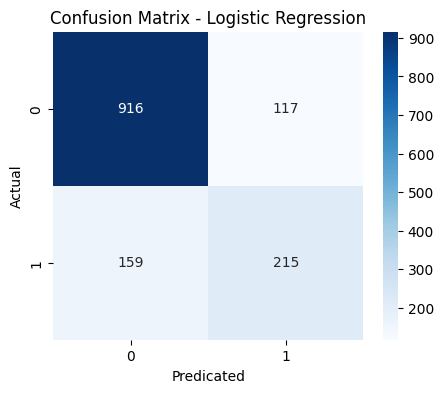

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report 
import seaborn as sns 
import matplotlib.pyplot as plt

#1) Logistic Regression:
y_pred_lr = model_lr.predict(X_test_scaled)

acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print("Logistic Regression Preformance:")
print("Accuracy:", acc_lr)
print("Precision:", prec_lr)
print("Recall:",rec_lr)
print("F1_Score:", f1_lr)

# Confusion Matrix:
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize= (5,4))
sns.heatmap(cm_lr, annot = True, fmt = 'd', cmap = 'Blues')
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicated")
plt.ylabel("Actual")
plt.show()

Random Forest Preformance:
Accuracy: 0.7882018479033405
Precision: 0.6233766233766234
Recall: 0.5133689839572193
F1_Score: 0.5630498533724341


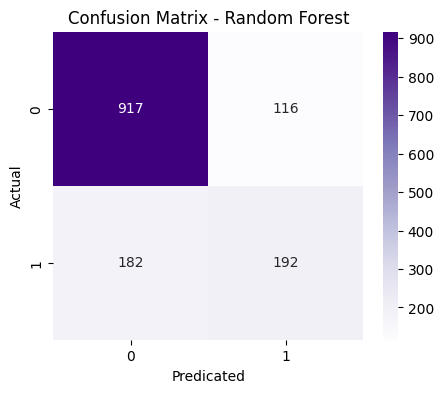

In [12]:
# 2) Random Forest:
y_pred_rf = model_rf.predict(X_test_scaled)

acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest Preformance:")
print("Accuracy:", acc_rf)
print("Precision:", prec_rf)
print("Recall:",rec_rf)
print("F1_Score:", f1_rf)

# Confusion Matrix:
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize= (5,4))
sns.heatmap(cm_rf, annot = True, fmt = 'd', cmap = 'Purples')
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicated")
plt.ylabel("Actual")
plt.show()

In [13]:
# Comparing the models:

import pandas as pd

comparison = pd.DataFrame({
"Model":["Logistic Regression","Random Forest" ],
"Accuracy":[acc_lr, acc_rf ],
"Precision":[prec_lr, prec_rf ],
"Recall":[rec_lr, rec_rf ],
"F1_Score":[f1_lr, f1_rf]  
})

print("\n Model Comparison:")
print(comparison)


 Model Comparison:
                 Model  Accuracy  Precision    Recall  F1_Score
0  Logistic Regression  0.803838   0.647590  0.574866  0.609065
1        Random Forest  0.788202   0.623377  0.513369  0.563050


# Interpretation of Results

Based on the evaluation matrics, the **Logistic Regression model** achieved higher performance compared to the **Random Forest model**, It obtained better accuracy, precision, recall, F1_score, which indicates that it was more effective in predicting customer churn for this dataset.

The confusion matrix also shows that **Logistic Regression** made fewer miscalssifications overall. This suggests that the relationships in the dataset are mostly linear, which aligns with the strengths of **Logistic Regression**.

**Random Forest**performed reasonably well but showed lower recall, meaning it missed more actual churn cases. This may be due to the dataset size or the need for further hyperparameter tuning.

*Overall,* **Logistic Regression** *is the more suitable model for this project, providing a balance between performance and interpretability*.